# LAB3 - Bài 5 (Trang 29): Gom cụm khối u lành tính / ác tính (Breast Cancer Wisconsin Diagnostic)
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, confusion_matrix, classification_report,
                             accuracy_score, adjusted_rand_score)
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 8)

dac_trung = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
             "concavity", "concave_points", "symmetry", "fractal_dimension"]
cot = ["ID", "Diagnosis"] + [f"{f}_{s}" for s in ["mean", "se", "worst"] for f in dac_trung]
df = pd.read_csv("wdbc.data", header=None, names=cot)
print("Kích thước:", df.shape)
print(df.head())

Đinh Nhật Huyền Nhân - 6451071055


Kích thước: (569, 32)
         ID Diagnosis  radius_mean  texture_mean  ...  concavity_worst  concave_points_worst  symmetry_worst  \
0    842302         M        17.99         10.38  ...           0.7119                0.2654          0.4601   
1    842517         M        20.57         17.77  ...           0.2416                0.1860          0.2750   
2  84300903         M        19.69         21.25  ...           0.4504                0.2430          0.3613   
3  84348301         M        11.42         20.38  ...           0.6869                0.2575          0.6638   
4  84358402         M        20.29         14.34  ...           0.4000                0.1625          0.2364   

   fractal_dimension_worst  
0                  0.11890  
1                  0.08902  
2                  0.08758  
3                  0.17300  
4                  0.07678  

[5 rows x 32 columns]


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
print("Số giá trị thiếu:", int(df.isnull().sum().sum()))
print("Phân bố nhãn chẩn đoán (B = lành tính, M = ác tính):")
print(df["Diagnosis"].value_counts())
print()
print(df[[c for c in df.columns if c.endswith("_mean")]].describe().T.round(3))

Đinh Nhật Huyền Nhân - 6451071055
Số giá trị thiếu: 0
Phân bố nhãn chẩn đoán (B = lành tính, M = ác tính):
Diagnosis
B    357
M    212
Name: count, dtype: int64

                        count     mean      std      min      25%      50%      75%       max
radius_mean             569.0   14.127    3.524    6.981   11.700   13.370   15.780    28.110
texture_mean            569.0   19.290    4.301    9.710   16.170   18.840   21.800    39.280
perimeter_mean          569.0   91.969   24.299   43.790   75.170   86.240  104.100   188.500
area_mean               569.0  654.889  351.914  143.500  420.300  551.100  782.700  2501.000
smoothness_mean         569.0    0.096    0.014    0.053    0.086    0.096    0.105     0.163
compactness_mean        569.0    0.104    0.053    0.019    0.065    0.093    0.130     0.345
concavity_mean          569.0    0.089    0.080    0.000    0.030    0.062    0.131     0.427
concave_points_mean     569.0    0.049    0.039    0.000    0.020    0.034    0.074   

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
X = df.drop(columns=["ID", "Diagnosis"]).values
y_true = (df["Diagnosis"] == "M").astype(int).values     # 1 = ác tính, 0 = lành tính
X_scaled = StandardScaler().fit_transform(X)
print("X_scaled:", X_scaled.shape, "| mean ≈", X_scaled.mean().round(4), "| std ≈", X_scaled.std().round(4))

Đinh Nhật Huyền Nhân - 6451071055
X_scaled: (569, 30) | mean ≈ -0.0 | std ≈ 1.0


Đinh Nhật Huyền Nhân - 6451071055


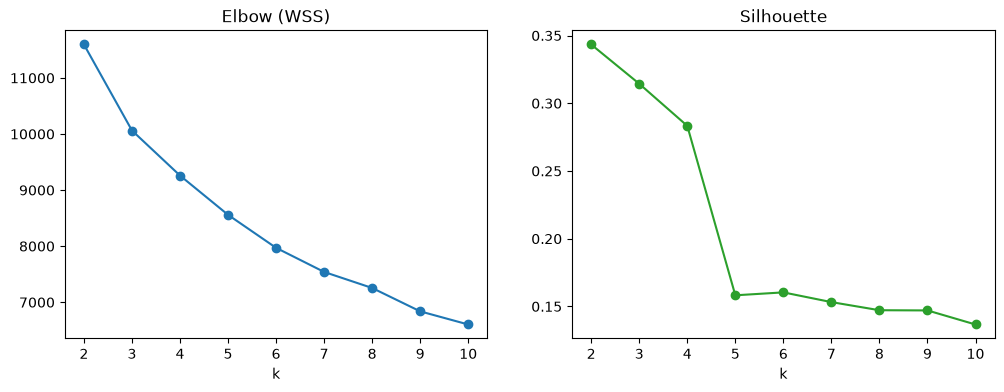

k =  2: WSS =  11595.53 | Silhouette = 0.3434
k =  3: WSS =  10061.80 | Silhouette = 0.3144
k =  4: WSS =   9258.99 | Silhouette = 0.2833
k =  5: WSS =   8558.66 | Silhouette = 0.1582
k =  6: WSS =   7970.26 | Silhouette = 0.1604
k =  7: WSS =   7540.32 | Silhouette = 0.1532
k =  8: WSS =   7254.33 | Silhouette = 0.1472
k =  9: WSS =   6837.63 | Silhouette = 0.1470
k = 10: WSS =   6603.40 | Silhouette = 0.1367


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
ks = range(2, 11)
wss, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    wss.append(km.inertia_); sil.append(silhouette_score(X_scaled, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), wss, "o-"); ax[0].set_title("Elbow (WSS)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-", color="tab:green"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.show()
for k, a, b in zip(ks, wss, sil):
    print(f"k = {k:2d}: WSS = {a:9.2f} | Silhouette = {b:.4f}")

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
print("Số mẫu mỗi cụm:", np.bincount(clusters))
print(f"Silhouette (k=2) = {silhouette_score(X_scaled, clusters):.4f}")
# Cụm nào có nhiều khối u ác tính hơn thì gán nhãn M
print(pd.crosstab(clusters, df["Diagnosis"], rownames=["Cụm"], colnames=["Chẩn đoán thật"]))
cum_ac_tinh = np.argmax([y_true[clusters == c].mean() for c in range(2)])
y_pred = (clusters == cum_ac_tinh).astype(int)
print("Cụm được gán là ác tính (M):", cum_ac_tinh)

Đinh Nhật Huyền Nhân - 6451071055
Số mẫu mỗi cụm: [375 194]
Silhouette (k=2) = 0.3434
Chẩn đoán thật    B    M
Cụm                     
0               339   36
1                18  176
Cụm được gán là ác tính (M): 1


Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.9051
Adjusted Rand Index: 0.6536
               precision    recall  f1-score   support

B (lành tính)     0.9040    0.9496    0.9262       357
  M (ác tính)     0.9072    0.8302    0.8670       212

     accuracy                         0.9051       569
    macro avg     0.9056    0.8899    0.8966       569
 weighted avg     0.9052    0.9051    0.9042       569



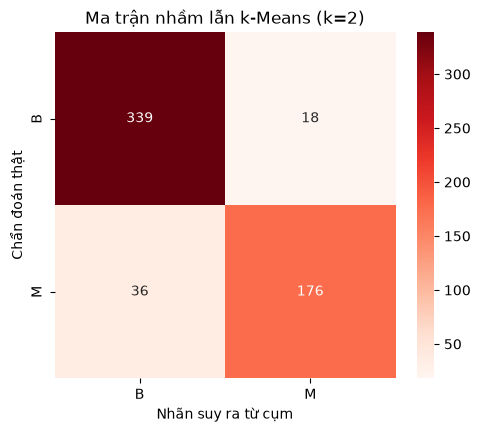

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y_true, clusters), 4))
print(classification_report(y_true, y_pred, target_names=["B (lành tính)", "M (ác tính)"], digits=4))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=["B", "M"], yticklabels=["B", "M"])
plt.xlabel("Nhãn suy ra từ cụm"); plt.ylabel("Chẩn đoán thật"); plt.title("Ma trận nhầm lẫn k-Means (k=2)")
plt.show()

Đinh Nhật Huyền Nhân - 6451071055
Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.4427 0.1897]


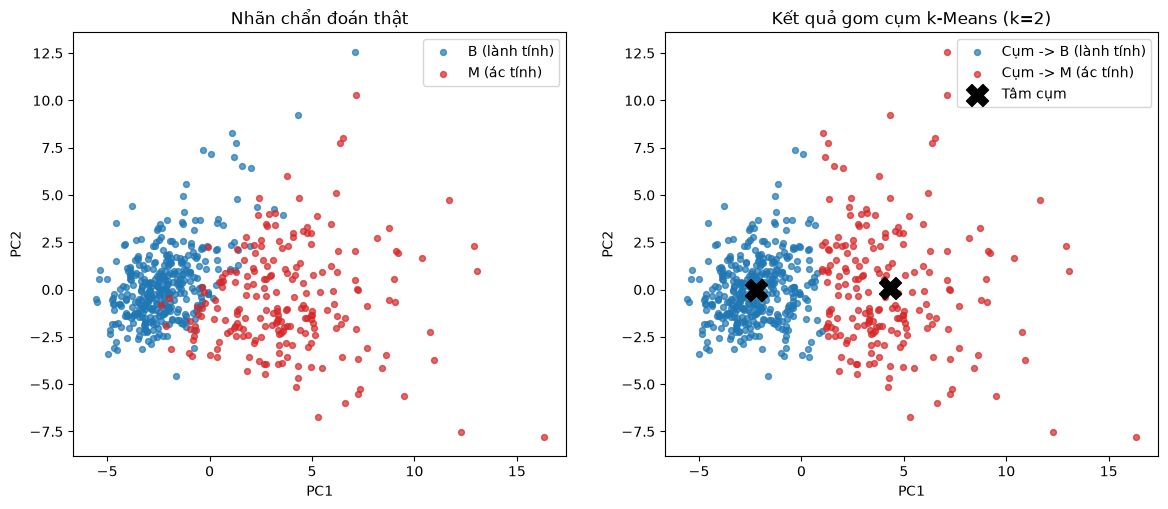

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_scaled)
tam = pca.transform(kmeans.cluster_centers_)
print("Tỷ lệ phương sai giải thích bởi 2 thành phần chính:", pca.explained_variance_ratio_.round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for v, ten, mau in [(0, "B (lành tính)", "tab:blue"), (1, "M (ác tính)", "tab:red")]:
    ax[0].scatter(Z[y_true == v, 0], Z[y_true == v, 1], s=18, alpha=0.7, c=mau, label=ten)
    ax[1].scatter(Z[y_pred == v, 0], Z[y_pred == v, 1], s=18, alpha=0.7, c=mau, label=f"Cụm -> {ten}")
ax[1].scatter(tam[:, 0], tam[:, 1], s=250, c="black", marker="X", label="Tâm cụm")
ax[0].set_title("Nhãn chẩn đoán thật"); ax[1].set_title("Kết quả gom cụm k-Means (k=2)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.legend()
plt.show()

- Dữ liệu gồm 569 khối u (357 lành tính B, 212 ác tính M) và 30 thuộc tính số, không có dữ liệu thiếu. Các thuộc tính có thang đo rất khác nhau (area ~ hàng trăm, smoothness ~ 0.1), vì vậy cần chuẩn hóa bằng StandardScaler trước khi gom cụm.
- Hệ số Silhouette lớn nhất tại k = 2 (0.343), phù hợp với hai nhóm lành tính và ác tính.
- k-Means (k=2) gom đúng 515/569 mẫu: Accuracy ≈ 0.905, ARI ≈ 0.654. Với lớp ác tính (M): Precision ≈ 0.907, Recall ≈ 0.830, F1 ≈ 0.867. Với lớp lành tính (B): Precision ≈ 0.904, Recall ≈ 0.950, F1 ≈ 0.926.
- Sai sót chủ yếu là 36 khối u ác tính bị gom vào cụm lành tính (âm tính giả). Trong y khoa đây là loại lỗi nguy hiểm, nên kết quả gom cụm chỉ dùng để tham khảo hoặc sàng lọc, không thay thế được mô hình phân lớp có giám sát hay chẩn đoán của bác sĩ.
- Biểu đồ PCA cho thấy hai nhóm tách khá rõ theo PC1. Vùng chồng lấn ở giữa là nơi k-Means gom nhầm.